In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
from InputCalculations import calc_statistical_descriptors
from model_definition import *


import joblib


#### What is the simplest workflow for making predictions (i.e. what do we require)
1. A way of describing the shape
    - This is easily obtained from the points folder

2. A Statistical description of the shape

2. A prediction dataset that is loaded into the ML model

3. A way to convert the predictions into probabilities to use in PCG
    - Maybe this could be added back into the .dat files or we could save another .mlp (Machine Learning Predictions) file that stores the predictions

In [2]:
### Helpers for loading data and distributions
def _load_dat_file(file_path):
    if "Outer" in file_path:
        print("Loading OuterBM.dat file...")
        rows_to_skip = 4  # Number of rows to skip at the beginning of the file
        column_line_index = 2  # The line index where the column names are located (0-based)
    else:
        print("Loading InnerBM.dat file...")
        rows_to_skip = 3  # Number of rows to skip at the beginning of the file
        column_line_index = 1  # The line index where the column names are located (0-based)
    
    # First we extract the column names from the second line of the file
    with open(file_path, 'r') as f:
        lines = f.readlines()
        column_names = lines[column_line_index].strip().split()[1:-1]
    
    # Then load the data into a pandas DataFrame, skipping the first three lines
    DF = pd.read_csv(file_path, skiprows=rows_to_skip, names=column_names, delimiter=r'\s+')
        
    H = 0.5 * (DF['C1'] + DF['C2']) # Mean curvature
    pos = DF[['X', 'Y', 'Z']].values
    area = DF['area'].values
    
    return DF, H, pos, area


# If you want to look into the upscaled predictions, use this function instead of loading from the raw .dat files
def load_from_Distributions(base_name, n_bins=100):
    """Loads the shape and area distributions from the Distributions folder and computes the density histogram."""
    Distribution_folder = os.path.join(current_dir, "..", "Distributions")
    all_H = np.load(os.path.join(Distribution_folder, "H" + base_name))
    all_A = np.load(os.path.join(Distribution_folder, "A" + base_name))
    
    bin_range = (all_H.min(), all_H.max()) # My own preference    
    shape_density, bin_edges = np.histogram(all_H, bins=n_bins, range=bin_range, weights=all_A, density=True)
    
    return shape_density, bin_edges


# Load an example of a finished model from Wall_runs
def load_reference_distribution(sys_name, rep, n_bins=100):
    data_dir = "/lustre/astro/rnl434/Data/Wall_runs"
    sys_dir = os.path.join(data_dir, sys_name)
    analysis_dir = os.path.join(sys_dir, "analysis")
    curvature_dir = os.path.join(analysis_dir, "curvatures")

    all_H = np.load(os.path.join(curvature_dir, f"rep{rep}_grid_curvature.npy"))
    all_A = np.load(os.path.join(curvature_dir, f"rep{rep}_grid_area.npy"))

    bin_range = (all_H.min(), all_H.max()) # My own preference
    shape_density, bin_edges = np.histogram(all_H, bins=n_bins, range=bin_range, weights=all_A, density=True)

    return shape_density, bin_edges

In [25]:
### Controller Region ###
n_bins = 100 # Number of bins for histogramming the shape distribution

# Specify the compositions the ML model should predict
C_CDL = 0.4
C_POPC = 0.6

In [26]:
# Specify the data that should be loaded
current_dir = os.getcwd()
point_dir = os.path.join(current_dir, "..", "System", "point")
Data_inner, H_inner, pos_inner, area_inner = _load_dat_file(os.path.join(point_dir, "InnerBM.dat"))
Data_outer, H_outer, pos_outer, area_outer = _load_dat_file(os.path.join(point_dir, "OuterBM.dat"))



# Create the shape and area arrays for the ML model input
all_H = np.concatenate((H_inner, H_outer))
all_A = np.concatenate((area_inner, area_outer))
bin_range = (all_H.min(), all_H.max()) # My own preference
shape_density, bin_edges = np.histogram(all_H, bins=n_bins, range=bin_range, weights=all_A, density=True)

Loading InnerBM.dat file...
Loading OuterBM.dat file...


In [27]:
### ML Helpers

def stat_to_input(stat_container, feature_columns, C_POPC, C_CDL, n_bins, bin_range):
    input_params = {key: None for key in feature_columns}

    # Add all the statistical descriptors to the input_params dictionary
    for i, key in enumerate(feature_columns):
        if key in stat_container:
            input_params[key] = stat_container[key]

    # Construct the bin_centers for the input data
    bin_edges = np.linspace(bin_range[0], bin_range[1], n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    input_params['H_i'] = bin_centers

    # Construct the concentration array for the input data
    input_params["C_ratio"] = C_CDL/C_POPC
    return input_params


def construct_ML_input(input_params):
    """Converts the filled input_params dictionary into a tensor suitable for the ML model."""
    n_bins = len(input_params['H_i'])
    input_tensor = torch.zeros((1, n_bins, len(input_params)))
    
    # fill the tensor with the values from input_params
    for i, key in enumerate(input_params):
        input_tensor[0, :, i] = torch.tensor(input_params[key], dtype=torch.float32)            
    return input_tensor.squeeze(0)  # Remove the first dimension to match the expected input shape for the model



def convert_to_prob(densities):
    """
    Convert densities to probabilities by normalizing each bin across lipids.
    """
    probabilites = []
    for data in densities:
        totals = data.sum(axis=0)  # total composition per bin, summed over lipids

        lipid_prob = np.divide(
            data, totals,
            out=np.zeros_like(data, dtype=float),
            where=totals > 0
        )
        probabilites.append(lipid_prob)
    return np.array(probabilites)

In [28]:
### Constructing the input tensor for the ML model

# Loading the model, the feature columns, and the scaler
model_dict = load_model("HardPINN", device="cpu")
model = model_dict["model"]
feature_columns = model_dict["feature_columns"]
scaler_X = model_dict["scaler_X"]

# From the parameters we create an empty dictionary to store the statistical descriptors
input_params = {key: None for key in feature_columns}
stat_container = calc_statistical_descriptors(all_H, all_A, n_bins=n_bins, bin_range=bin_range)
input_params = stat_to_input(stat_container, feature_columns, C_POPC=C_POPC, C_CDL=C_CDL, n_bins=n_bins, bin_range=bin_range)
input_tensor = construct_ML_input(input_params)

# Scaling the input tensor using the pre-fitted scaler (and converting it back to a tensor)
input_tensor_scaled = torch.tensor(scaler_X.transform(input_tensor.numpy()), dtype=torch.float32)

In [29]:
# Make predictions using the ML model
model.eval()
with torch.no_grad():
    
    # Unsqueeze the input tensor to remove the batch dimension
    compositions = torch.tensor([[C_POPC, C_CDL]], dtype=torch.float32).squeeze()
    dH = input_params['H_i'][1] - input_params['H_i'][0]
    shape_density = torch.tensor(shape_density, dtype=torch.float32).squeeze()  # Convert shape_density to a tensor
    input_tensor_scaled = input_tensor_scaled.squeeze()
    
    # Predict the phi values using the model
    phi_predict = model(input_tensor_scaled, shape_density, compositions, dH).numpy()

    
    rho_predict = []
    for i in range(len(phi_predict)):
        rho_predict.append(phi_predict[i] * shape_density.numpy()[i] / dH)
    rho_predict = np.array(rho_predict)

    probabilities = convert_to_prob(rho_predict)

Predicting compositions: C_POPC = 0.6, C_CDL = 0.4


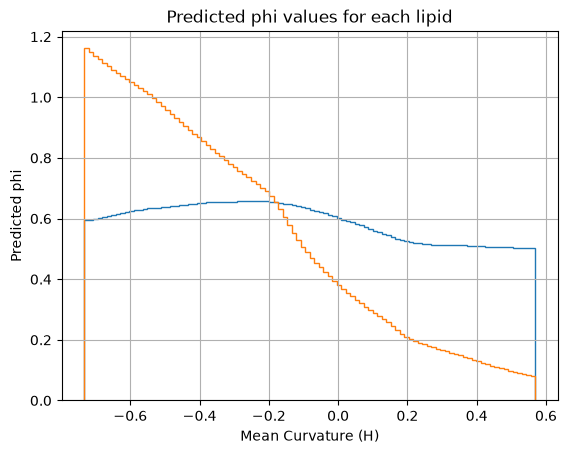

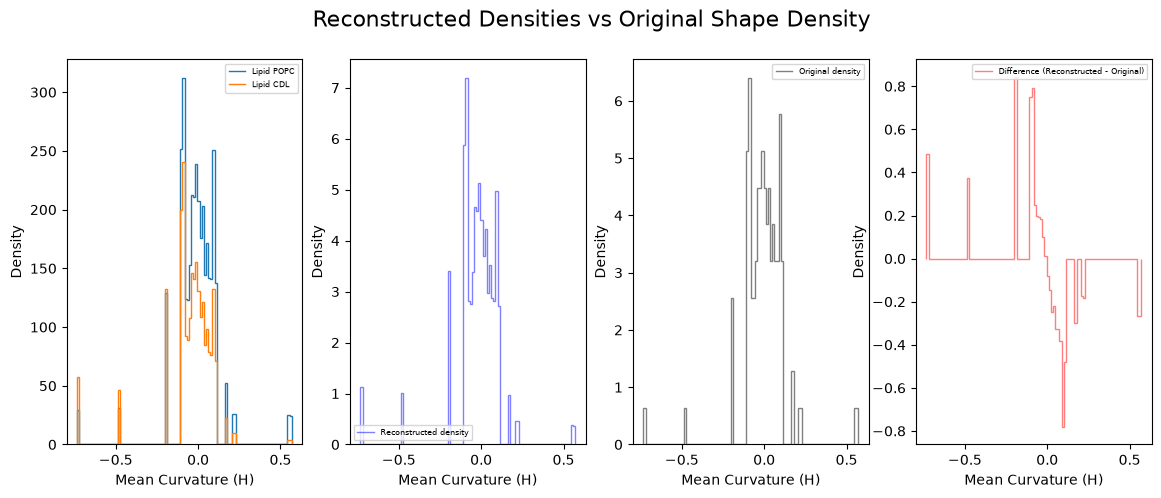

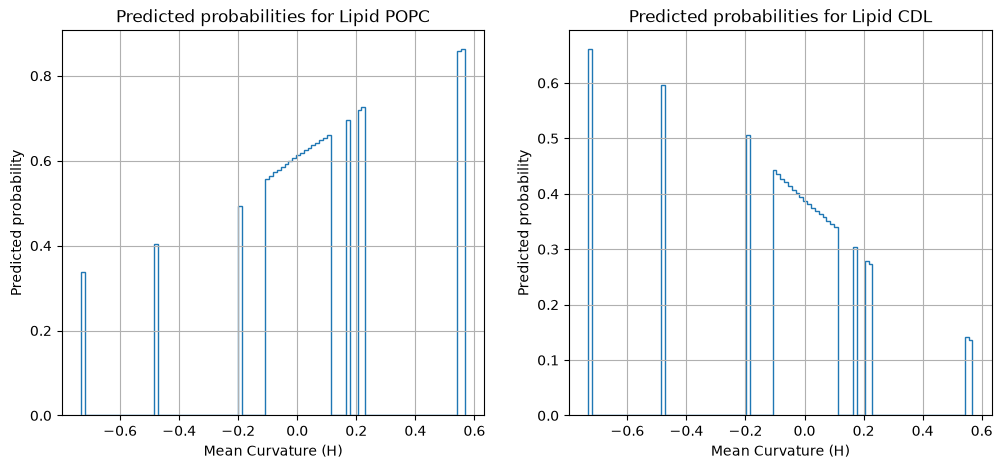

In [31]:
### PLOTTING ###
# Plotting the predicted phi values
lipid_labels = ['POPC', 'CDL']
fig, ax = plt.subplots()
for i in range(phi_predict.shape[1]):
    ax.stairs(phi_predict[:, i], bin_edges, label=f'Predicted phi (Lipid {lipid_labels[i]})')
ax.set_xlabel('Mean Curvature (H)')
ax.set_ylabel('Predicted phi')
ax.set_title('Predicted phi values for each lipid')
ax.grid()


# Plotting the reconstructed densities
fig, ax = plt.subplots(1, 4, figsize=(14, 5))
for i in range(rho_predict.shape[1]):
    ax[0].stairs(rho_predict[:, i], bin_edges, label=f'Lipid {lipid_labels[i]}')


# Normalize the totals to ensure they sum to 1 for comparison with the original shape density
totals = rho_predict.sum(axis=1)/np.sum(rho_predict.sum(axis=1) * dH)  # Normalize the totals to sum to 1

# difference between the reconstructed density and the original shape density
density_difference = totals - shape_density.numpy()

# Compare the combined reconstructed density with the original shape density
ax[1].stairs(totals, bin_edges, label='Reconstructed density', color='blue', linewidth=1, alpha=0.5)
ax[2].stairs(shape_density, bin_edges, label='Original density', color='black', linewidth=1, alpha=0.5)
ax[3].stairs(density_difference, bin_edges, label='Difference (Reconstructed - Original)', color='red', linewidth=1, alpha=0.5)
for a in ax:
    a.set_xlabel('Mean Curvature (H)')
    a.set_ylabel('Density')
    a.legend(fontsize=6)
fig.suptitle('Reconstructed Densities vs Original Shape Density', fontsize=16)


# Plotting the probabilities
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for i in range(probabilities.shape[1]):
    ax[i].stairs(probabilities[:, i], bin_edges, label=f'Lipid {lipid_labels[i]}')
for i, a in enumerate(ax):
    a.set_xlabel('Mean Curvature (H)')
    a.set_ylabel('Predicted probability')
    a.set_title(f'Predicted probabilities for Lipid {lipid_labels[i]}')
    a.grid()



print(f"Predicting compositions: C_POPC = {C_POPC}, C_CDL = {C_CDL}")